# 04 사용자 질문 의도에 따라 일반답변/웹검색/문서검색을 하는 RAG

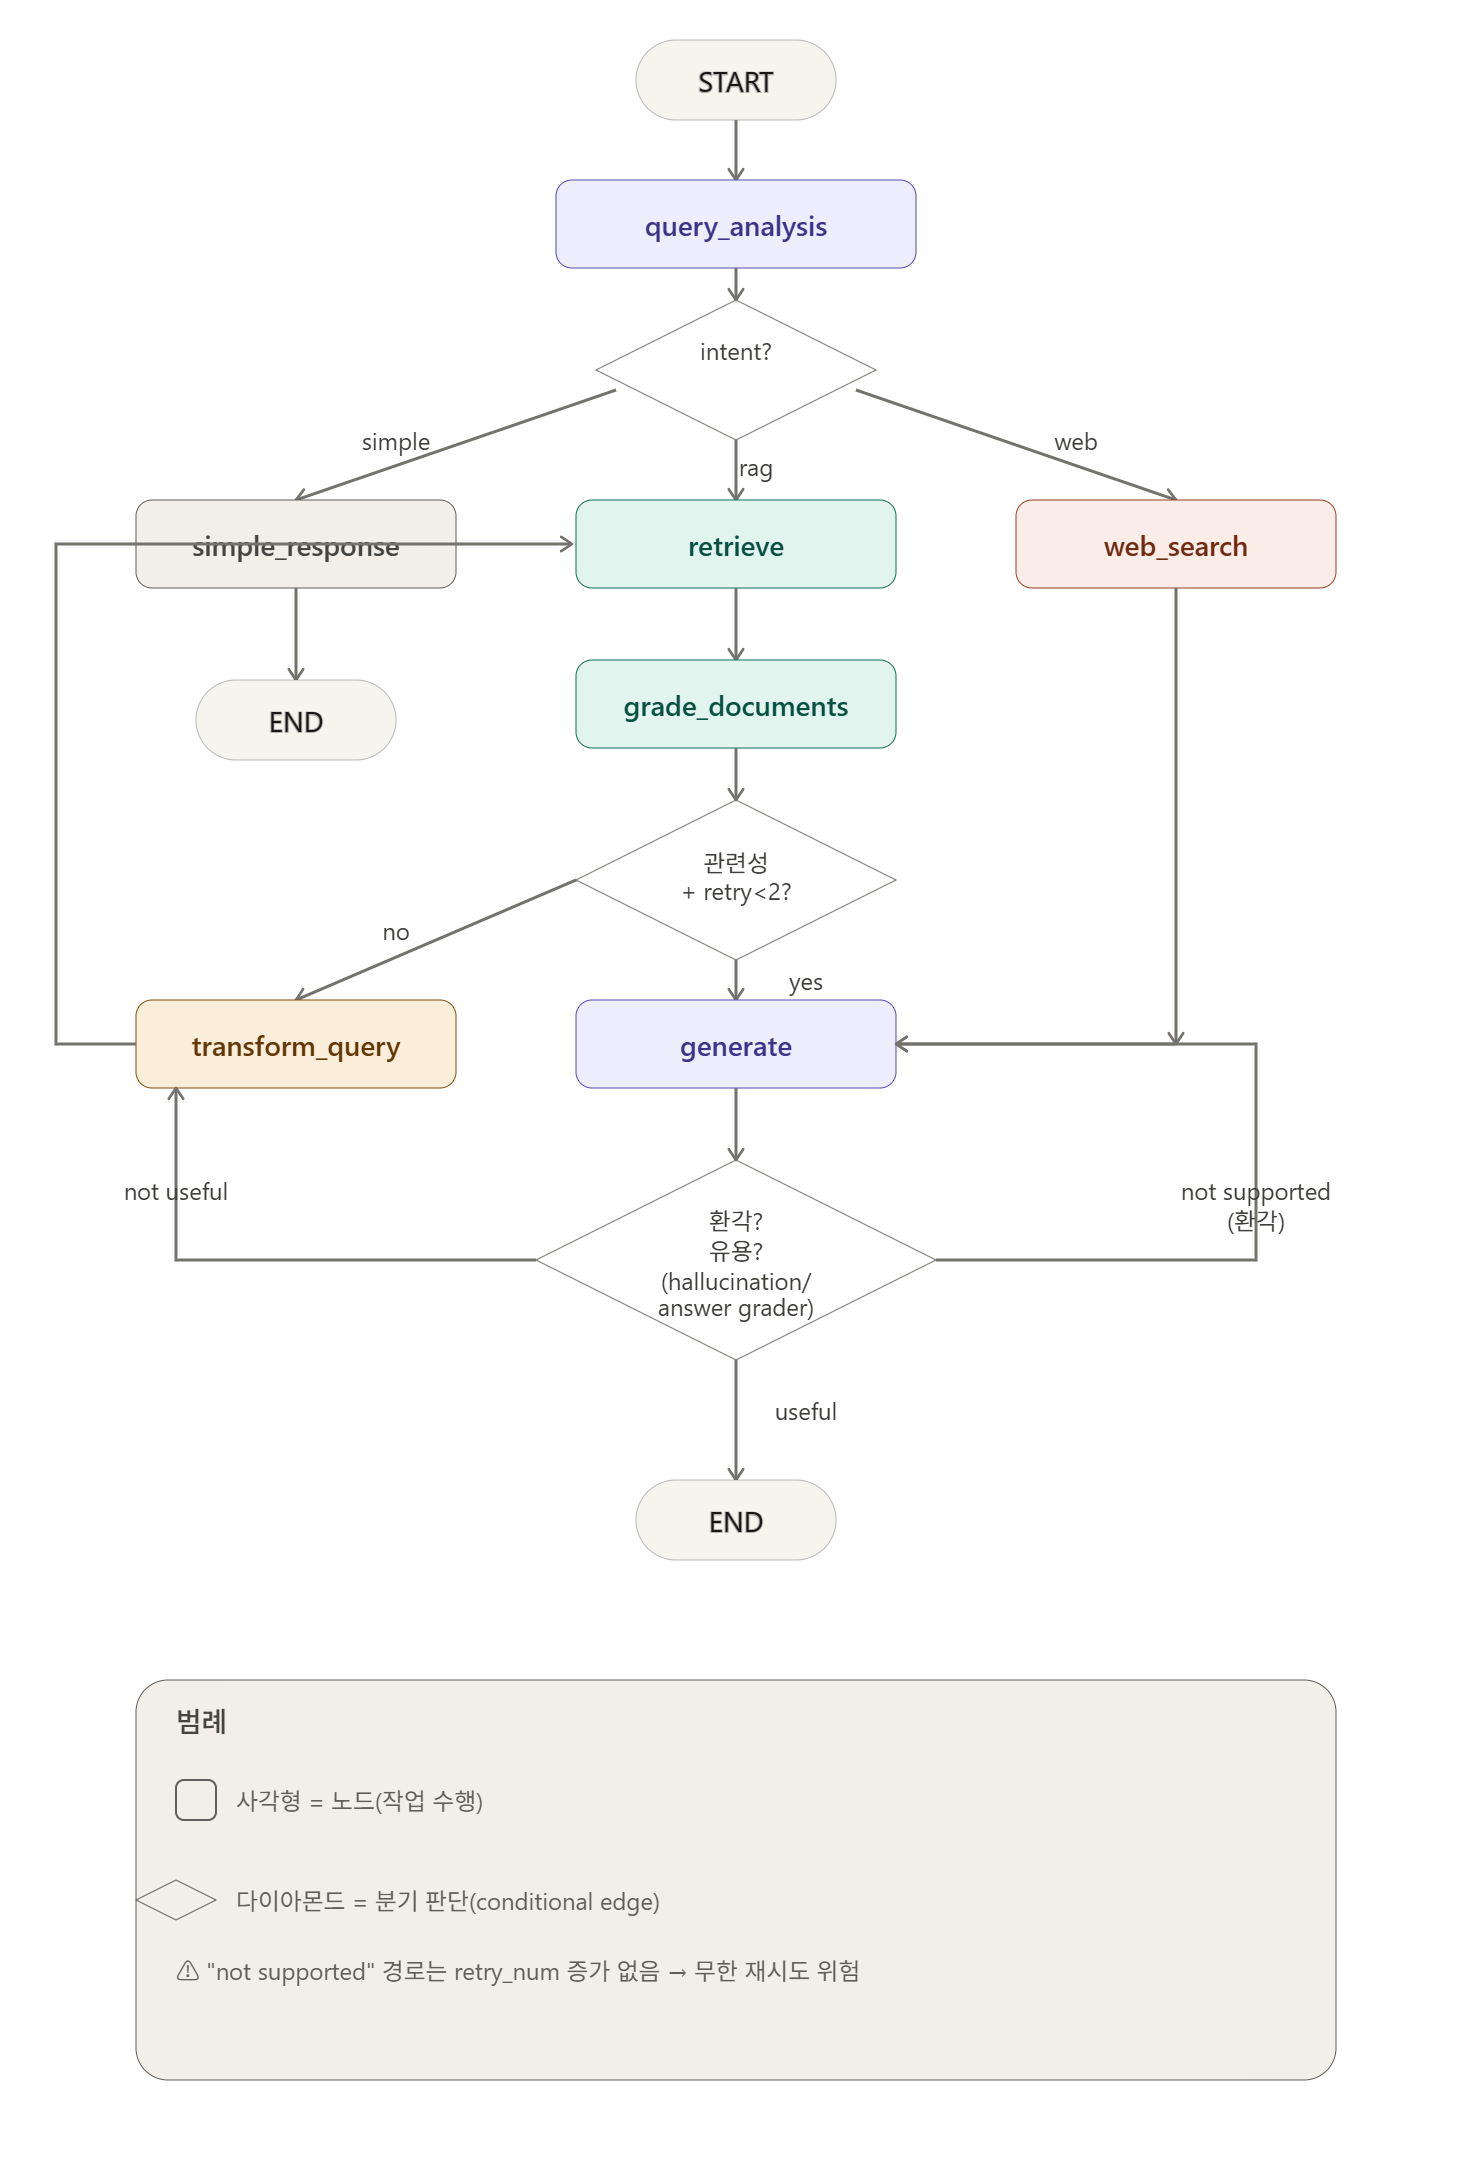

 # Graph State 정의

 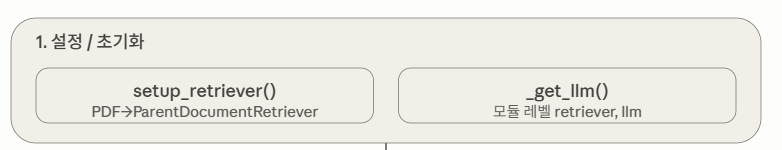

In [2]:
from langgraph.graph import MessagesState
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
from typing_extensions import TypedDict
from typing import Optional

load_dotenv()  # .env 파일에서 환경변수(API 키 등) 불러오기


def _get_llm():
    # 사용할 LLM 모델 초기화해서 반환
    return init_chat_model("gpt-5.4-mini")


class InputState(TypedDict):
    # 그래프 입력으로 받는 상태 (사용자 질문만 포함)
    question: str


class OutputState(TypedDict):
    # 그래프 최종 출력 상태 (생성된 답변만 포함)
    generation: str


class State(MessagesState):
    # 그래프 전체에서 공유되는 상태 (MessagesState 상속 -> messages 필드 자동 포함)
    question: Optional[str]        # 사용자 질문
    generation: Optional[str]      # LLM이 생성한 답변
    document: Optional[str]        # 검색/RAG 등으로 가져온 문서 내용
    intent: Optional[str]          # 질의 분석 결과: 'simple' / 'rag' / 'web' 중 하나
    retry_num: int = 0              # 재시도 횟수 (기본값 0)

c:\Users\jino7\Desktop\llm_engineering-main\.venv\Lib\site-packages\langgraph\cache\base\__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


 # Retriever 설정

In [3]:
import fitz  # PyMuPDF - PDF 파일을 읽기 위한 라이브러리
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_classic.retrievers import ParentDocumentRetriever
from langchain_core.stores import InMemoryByteStore
from langchain_core.tools import create_retriever_tool


def setup_retriever():
    file_path = "dataset/SPRi AI Brief 6월호.pdf"

    # ---- 1. PyMuPDF로 PDF 문서 로드 ----
    doc = fitz.open(file_path)
    docs = []
    for page_num in range(len(doc)):
        page = doc[page_num]
        text = page.get_text("text", sort=True)  # 페이지 텍스트 추출 (읽기 순서대로 정렬)
        # LangChain Document 형식으로 변환 (페이지 1개 = Document 1개)
        docs.append(
            Document(
                page_content=text,
                metadata={
                    "source": file_path,
                    "page": page_num + 1  # 페이지 번호는 1부터 시작하도록 보정
                }
            )
        )
    doc.close()  # 파일 핸들 닫기
    print(f"총 {len(docs)}페이지 로드 완료")

    # ---- 2. child_splitter 정의 ----
    # 검색(임베딩)용 작은 단위 청크 분할기 (400자, 50자 중첩)
    child_splitter = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=50)

    # ---- 3. 벡터스토어 생성 (메모리 전용, 디스크 저장 없음) ----
    embeddings = OpenAIEmbeddings()
    vectorstore = Chroma(
        collection_name="june_doc",
        embedding_function=embeddings
    )

    # ---- 4. parent 문서 저장용 docstore (메모리 기반 key-value 저장소) ----
    docstore = InMemoryByteStore()

    # ---- 5. ParentDocumentRetriever 생성 ----
    # child(작은 청크)로 검색하고, 매칭되면 parent(페이지 전체)를 반환하는 구조
    parent_retriever = ParentDocumentRetriever(
        vectorstore=vectorstore,      # child 청크 임베딩 저장
        docstore=docstore,            # parent 문서(페이지) 저장
        child_splitter=child_splitter,
        parent_splitter=None,         # parent_splitter 없음 -> 페이지 자체가 parent 단위
        search_kwargs={"k": 1}        # 검색 시 top-1 결과만 반환
    )

    # ---- 6. 문서를 retriever에 추가 (내부적으로 child 분할 + 임베딩 + docstore 저장) ----
    print("문서를 벡터스토어에 추가 중...")
    parent_retriever.add_documents(docs)

    # child/parent 개수 확인 (디버깅용 로그)
    child_count = vectorstore._collection.count()
    parent_count = len(list(docstore.yield_keys()))
    print(f"child chunk 수: {child_count}, parent page 수: {parent_count}")

    # ---- 7. Agent가 호출할 수 있는 Retriever Tool로 래핑 ----
    retriever_tool = create_retriever_tool(
        parent_retriever,
        "retrieve_AI_brief",  # 도구 이름
        "AI 기술 관련 정보를 SPRi AI Brief에서 검색하고 반환합니다.",  # 도구 설명 (LLM이 참고)
    )

    return parent_retriever, retriever_tool

# 프롬프트 정의

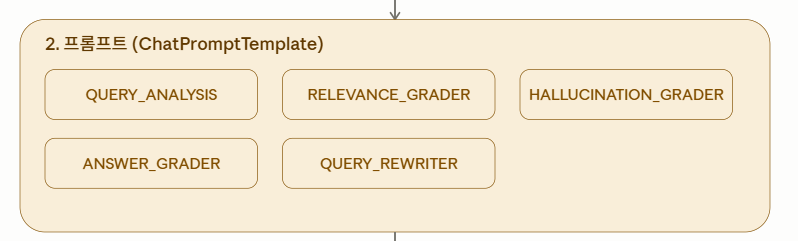

In [4]:
from langchain_core.prompts import ChatPromptTemplate


# 질문 분석 프롬프트 (의도 파악)
QUERY_ANALYSIS_PROMPT = ChatPromptTemplate.from_template(
    """
    당신은 사용자 질문의 의도를 파악하는 분석가입니다.

    질문을 분석하여 다음 중 하나로 분류하세요:

    1. 'simple': 간단한 대화, 인사, 감정 표현 (예: "안녕", "고마워", "잘가")
    2. 'rag': AI 기술/산업 관련 질문 (AI Brief 문서에서 찾을 수 있는 내용)
       - 생성형 AI, LLM, AI 정책, AI 산업 동향 등
    3. 'web': 일반적인 지식, 최신 정보, AI Brief와 무관한 질문
       - 날씨, 뉴스, 일반 지식, 코딩 방법 등

    <question>
    {question}
    </question>

    위 질문을 분석하여 'simple', 'rag', 'web' 중 하나를 반환하세요.
    """
)
# {question} 자리에 실제 사용자 질문이 들어가서 LLM에 전달됨
# 이 프롬프트의 출력값이 State의 intent 필드('simple'/'rag'/'web')로 들어가서
# add_conditional_edges에서 분기 라우팅에 사용될 것으로 보임

In [5]:
from langchain_core.prompts import ChatPromptTemplate

# 문서 관련성 평가 프롬프트 (Retrieval Grading)
RELEVANCE_GRADER_PROMPT = ChatPromptTemplate.from_template(
    """
    당신은 사용자 질문에 대한 검색된 문서의 관련성을 평가하는 평가자입니다.

    <context>
    {context}
    </context>

    <question>
    {question}
    </question>

    문서가 사용자 질문과 관련된 키워드나 의미를 포함하고 있다면, 관련성이 있다고 평가하세요.
    엄격한 테스트일 필요는 없습니다. 목표는 잘못된 검색 결과를 걸러내는 것입니다.

    관련성이 있는 경우 'yes', 관련성이 없는 경우 'no'를 반환하세요.
    """
)
# {context}: retriever가 검색해온 문서(parent page) 내용이 들어감
# {question}: 사용자 원본 질문이 들어감
# 출력은 'yes'/'no' 이진 분류 -> RAG 결과가 부적합하면 web 검색 등으로 재라우팅하는
# Self-RAG / CRAG 스타일의 grading 노드에서 사용될 것으로 보임

In [6]:
from langchain_core.prompts import ChatPromptTemplate

# 환각(hallucination) 평가 프롬프트
HALLUCINATION_GRADER_PROMPT = ChatPromptTemplate.from_template(
    """
    당신은 LLM이 생성한 답변이 검색된 사실에 근거하고 있는지 평가하는 평가자입니다.

    <facts>
    {document}
    </facts>

    <generation>
    {generation}
    </generation>

    답변이 주어진 사실에 근거하고 있으면 'yes', 그렇지 않으면 'no'를 반환하세요.
    'yes'는 답변이 사실 세트에 의해 뒷받침된다는 의미입니다.
    """
)
# {document}: retriever가 가져온 근거 문서(parent page) 내용
# {generation}: LLM이 실제로 생성한 답변 텍스트
# 출력은 'yes'/'no' -> 'no'(근거 없음/환각)인 경우 재생성(retry) 


In [7]:
from langchain_core.prompts import ChatPromptTemplate

# 답변 유용성 평가 프롬프트 (Answer Grading)
ANSWER_GRADER_PROMPT = ChatPromptTemplate.from_template(
    """
    당신은 답변이 질문에 대해 유용한 정보를 제공하는지 평가하는 평가자입니다.

    <question>
    {question}
    </question>

    <generation>
    {generation}
    </generation>

    다음 기준으로 평가하세요:
    - 답변이 질문의 핵심 의도에 대응하는가?
    - 질문에서 요청한 정보를 실질적으로 제공하는가?
    - 답변 내용이 질문과 관련성이 있는가?

    답변이 질문에 대해 의미 있는 정보를 제공한다면 'yes'를 반환하세요.
    답변이 질문과 완전히 무관하거나 요청한 정보를 전혀 제공하지 않을 때만 'no'를 반환하세요.

    관대하게 평가하세요. 답변이 부분적으로라도 질문에 답하고 있다면 'yes'입니다.
    """
)
# {question}: 사용자 원본 질문
# {generation}: LLM이 생성한 최종 답변
# 출력은 'yes'/'no' -> hallucination_grader(근거 충실성)와는 별개로
# "질문에 실제로 도움이 되는 답변인가"를 평가하는 단계

In [8]:
from langchain_core.prompts import ChatPromptTemplate

# 쿼리 재작성 프롬프트 (Query Rewriting)
QUERY_REWRITER_PROMPT = ChatPromptTemplate.from_template(
    """
    당신은 입력된 질문을 벡터스토어 검색에 최적화된 더 나은 버전으로 변환하는 질문 재작성자입니다.
    입력을 보고 근본적인 의미적 의도를 추론하세요.

    <question>
    {question}
    </question>

    위 질문을 개선하여 한국어로 재작성하세요.
    """
)
# {question}: 원본(또는 이전에 실패한) 사용자 질문
# 출력: 검색에 더 적합하게 다듬어진 새 질문 텍스트


# 초기화



In [9]:
# 모듈 레벨에서 한 번만 초기화
# (그래프 노드 함수들이 매번 새로 만들지 않고 이 retriever/llm을 재사용하도록)
retriever, retriever_tool = setup_retriever()  # PDF 기반 ParentDocumentRetriever + 검색 도구
llm = _get_llm()  # 그래프 전체에서 공통으로 쓸 LLM 인스턴스

총 28페이지 로드 완료
문서를 벡터스토어에 추가 중...
child chunk 수: 191, parent page 수: 28


# Pydantic Models

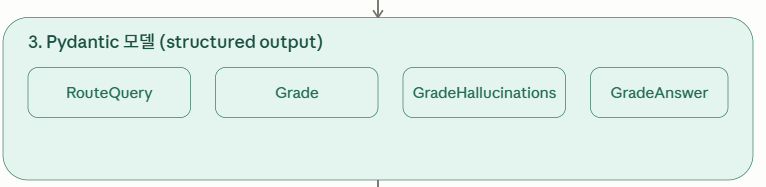

In [10]:
from pydantic import BaseModel, Field

# ===============================
# Pydantic Models
# ===============================
# LLM의 structured output을 강제하기 위한 모델들
# (각 프롬프트의 출력을 자유 텍스트가 아닌 정해진 필드로 받기 위함)

class RouteQuery(BaseModel):
    """질문 의도 분류"""
    intent: str = Field(
        description="질문의 의도: 'simple' (간단한 대화), 'rag' (AI 문서 검색), 'web' (웹 검색)"
    )
    # QUERY_ANALYSIS_PROMPT 결과를 받는 모델 -> State.intent에 매핑됨


class Grade(BaseModel):
    """Binary score for relevance check."""
    binary_score: str = Field(description="Relevance score 'yes' or 'no'")
    # RELEVANCE_GRADER_PROMPT 결과를 받는 모델 (문서-질문 관련성 yes/no)


class GradeHallucinations(BaseModel):
    """Binary score for hallucination present in generation answer."""
    binary_score: str = Field(
        description="Answer is grounded in the facts, 'yes' or 'no'"
    )
    # HALLUCINATION_GRADER_PROMPT 결과를 받는 모델 (답변의 근거 충실성 yes/no)


class GradeAnswer(BaseModel):
    """Binary score to assess answer addresses question."""
    binary_score: str = Field(
        description="Answer addresses the question, 'yes' or 'no'"
    )
    # ANSWER_GRADER_PROMPT 결과를 받는 모델 (답변의 질문 적합성 yes/no)

# Nodes

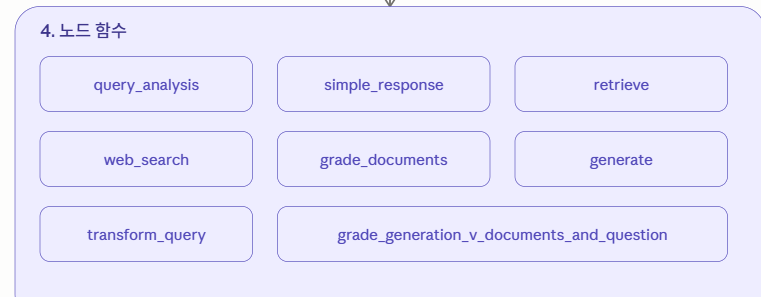

def query_analysis(state: State):

In [11]:
from typing import Literal
from langchain_core.messages import HumanMessage, SystemMessage


def query_analysis(state: State):
    """
    질문의 의도를 분석합니다.
    simple: 간단한 대화 → 직접 답변
    rag: AI 문서 검색 → retrieve
    web: 웹 검색 → web_search
    """
    print("##### QUERY ANALYSIS #####")

    question = state["question"]
    print(f"Analyzing question: {question}")

    # LLM으로 질문 분석
    llm = _get_llm()  # 모듈 레벨 llm이 있는데 여기서 새로 또 생성 (중복 호출, 통일 고려해볼 부분)
    router = llm.with_structured_output(RouteQuery)  # 출력을 RouteQuery 스키마로 강제 -> intent 필드 보장
    chain = QUERY_ANALYSIS_PROMPT | router  # 프롬프트 -> LLM(구조화 출력) 체인 구성

    result = chain.invoke({"question": question})  # {question} 변수를 채워서 실행
    intent = result.intent  # RouteQuery.intent ('simple'/'rag'/'web') 추출

    print(f"Intent: {intent}")

    # State 업데이트: question은 그대로 유지, intent를 새로 채워서 반환
    # 이후 add_conditional_edges에서 이 intent 값으로 분기 라우팅됨
    return {"question": question, "intent": intent}

def simple_response(state: State):

In [12]:
def simple_response(state: State):
    """
    간단한 대화에 대해 직접 답변합니다.
    """
    print("##### SIMPLE RESPONSE #####")

    question = state["question"]
    llm = _get_llm()  # 여기서도 전역 llm 재사용 가능한 부분 (위와 동일한 패턴)

    # 별도 프롬프트 없이 질문 그대로 HumanMessage로 LLM에 전달
    response = llm.invoke([HumanMessage(content=question)])

    print(f"Response: {response.content}")

    # generation: 최종 답변 텍스트 저장
    # messages: MessagesState의 누적 메시지 리스트에 AIMessage 추가
    #          (add_messages 리듀서가 자동으로 append 처리)
    return {"generation": response.content, "messages": [response]}

In [13]:
def retrieve(state: State):
    """
    벡터스토어에서 관련 문서를 검색합니다.
    """
    print("##### RETRIEVE #####")

    question = state["question"]
    print(f"Question: {question}")

    # 문서 검색 (전역 retriever = ParentDocumentRetriever 사용)
    # child 청크로 매칭 -> parent(페이지 전체) Document 리스트 반환
    documents = retriever.invoke(question)

    # 검색 결과를 LLM에 넘길 하나의 문자열(context)로 합치기
    context = ""
    for idx, doc in enumerate(documents):
        context += f"Document {idx + 1}:\n{doc.page_content}\n{doc.metadata}\n"
        print(f"Retrieved Document {idx + 1}: {doc.page_content[:100]}...")  # 앞 100자만 로그 출력

    # document: 합쳐진 검색 결과 텍스트 -> 이후 relevance_grader, generate, hallucination_grader에서 사용
    return {"document": context, "question": question}

In [14]:
def web_search(state: State):
    """
    웹 검색을 수행합니다.
    """
    print("##### WEB SEARCH #####")
    from langchain_tavily import TavilySearch  # type: ignore  # 함수 안에서 지연 import (모듈 레벨 로딩 부담 줄이기 위함)

    question = state["question"]
    print(f"Question: {question}")

    # 웹 검색 도구 생성 후 실행 (최대 3개 결과, 일반 주제)
    search_tool = TavilySearch(max_results=3, topic="general")
    results = search_tool.invoke(question)

    # 결과를 LLM이 읽기 좋은 하나의 문자열(context)로 포맷팅
    context = ""
    if isinstance(results, list):
        # 결과가 리스트 형태로 오는 경우 (정상적인 경우)
        for idx, result in enumerate(results):
            if isinstance(result, dict):
                # dict 형태 결과: 제목/내용/출처를 보기 좋게 정리
                context += f"\n[웹 검색 결과 {idx + 1}]\n"
                context += f"제목: {result.get('title', 'N/A')}\n"
                context += f"내용: {result.get('content', 'N/A')}\n"
                context += f"출처: {result.get('url', 'N/A')}\n"
            else:
                # dict가 아닌 경우 그냥 문자열로 변환
                context += f"\n[웹 검색 결과 {idx + 1}]: {result}\n"
    else:
        # 결과가 리스트가 아닌 경우 (예외적인 응답 형태) 통째로 문자열 변환
        context = str(results)

    print(f"Web search completed")

    # document: 웹 검색 결과 텍스트 -> retrieve 노드와 동일하게 generate 단계에서 사용됨
    return {
        "document": context,
        "question": question
    }

In [15]:
def grade_documents(state: State):
    """
    검색된 문서가 질문과 관련이 있는지 평가합니다.
    """
    print("##### CHECK RELEVANCE #####")

    question = state["question"]
    document = state["document"]

    # 관련성 평가 체인 구성
    llm = _get_llm()
    grader = llm.with_structured_output(Grade)  # 출력을 Grade 스키마(binary_score)로 강제
    chain = RELEVANCE_GRADER_PROMPT | grader

    score = chain.invoke({"question": question, "context": document})
    grade = score.binary_score  # 'yes' 또는 'no'

    print(f"Question: {question}")
    print(f"Context: {document[:100]}...")  # 문서 앞 100자만 로그
    print(f"Grade: {grade}")

    if grade == "yes":
        # 관련 있음 -> document 그대로 유지하고 다음 단계(generate)로 진행
        print("---GRADE: DOCUMENT RELEVANT---")
        return {"document": document, "question": question, "retry_num": state.get("retry_num", 0)}
    else:
        # 관련 없음 -> document를 빈 문자열로 비움
        # (이후 conditional edge에서 document가 비었으면 rewrite/web_search 등으로 재라우팅할 것으로 보임)
        print("---GRADE: DOCUMENT NOT RELEVANT---")
        return {"document": "", "question": question, "retry_num": state.get("retry_num", 0)}

In [16]:
def generate(state: State):
    """
    검색된 문서를 기반으로 최종 답변을 생성합니다.
    RAG 문서 또는 웹 검색 결과를 모두 처리할 수 있습니다.
    """
    print("##### GENERATE #####")
    question = state["question"]
    document = state.get("document", "")
    if not document:
        print("Warning: No document found, using empty context")
    print(f"Question: {question}")
    print(f"Context: {document[:100] if document else 'No context'}...")

    # RAG/웹검색 결과를 함께 답변에 반영하기 위한 시스템 프롬프트
    llm = _get_llm()
    SYSTEM_PROMPT = """
    당신은 관련 문서를 기반으로 답변하는 어시스턴트입니다.
    주어진 문서 텍스트를 기반으로 사용자의 질문에 대해 충실히 답변하세요.
    <rules>
    - context에 제공된 문서의 출처를 언급하며 답변을 작성하세요.
    - 문서가 RAG에서 온 경우: 파일명과 페이지 번호를 명시하세요.
    - 문서가 웹 검색에서 온 경우: 출처 URL을 명시하세요.
    - 답변은 마크다운 문법 형식으로 적절한 볼드체, 제목, 불렛 등을 사용하여 가독성 좋게 작성하세요.
    </rules>
    <output_format>
    답변은 아래와 같은 예시를 참고하여 구조적으로 작성하세요:
    [답변 본문]
    ===
    [출처]
    - RAG 문서: 파일명과 페이지 번호
    - 웹 검색: URL
    </output_format>
    """
    system_msg = SystemMessage(SYSTEM_PROMPT)
    # document와 question을 함께 담아 사용자 메시지 구성 (document 없으면 "문서 없음" 표시)
    human_msg = HumanMessage(f"""
    다음은 주어진 문서 텍스트입니다.
    <context>
    {document if document else "문서 없음"}
    </context>
    <question>
    {question}
    </question>
    """)

    response = llm.invoke([system_msg, human_msg])
    print(f"Response: {response.content[:100]}...")

    return {
        "document": document,   
        "question": question,
        "generation": response.content,
        "messages": [response],
        "retry_num": state.get("retry_num", 0)
    }

In [17]:
def transform_query(state: State):
    """
    검색 성능 향상을 위해 질문을 재작성합니다.
    """
    print("##### TRANSFORM QUERY #####")

    question = state["question"]

    # 쿼리 재작성 체인 (structured output 아님, 그냥 텍스트로 재작성된 질문을 받음)
    llm = _get_llm()
    question_rewriter = QUERY_REWRITER_PROMPT | llm
    better_question = question_rewriter.invoke({"question": question})

    print(f"Original Question: {question}")
    print(f"Better Question: {better_question.content}")

    return {
        "question": better_question.content,  # 재작성된 질문으로 State.question 갱신 -> retrieve 재시도용
        "messages": [better_question],         # 대화 히스토리에도 AIMessage로 기록
        "retry_num": state.get("retry_num", 0) + 1  # 여기서 재시도 횟수 +1 (무한루프 방지용 카운터)
    }

# 엣지 조건 함수

In [18]:
def route_question(state: State) -> Literal["simple_response", "retrieve", "web_search"]:
    """
    Query Analysis 결과에 따라 질문을 라우팅합니다.
    simple: simple_response (직접 답변)
    rag: retrieve (RAG 플로우)
    web: web_search (웹 검색)
    """
    print("##### ROUTE QUESTION #####")

    # query_analysis 노드가 채워준 intent 값 읽기 (없으면 기본값 'rag')
    intent = state.get("intent", "rag")

    if intent == "simple":
        # 간단한 대화 -> 바로 답변 노드로
        print("---ROUTE DECISION: SIMPLE CONVERSATION---")
        return "simple_response"
    elif intent == "rag":
        # AI 문서 관련 질문 -> 벡터스토어 검색 노드로
        print("---ROUTE DECISION: RAG SEARCH---")
        return "retrieve"
    else:  # web
        # 그 외(일반 지식/최신 정보) -> 웹 검색 노드로
        print("---ROUTE DECISION: WEB SEARCH---")
        return "web_search"

In [19]:
def decide_to_generate(state: State) -> Literal["transform_query", "generate"]:
    """
    문서 관련성에 따라 답변 생성 또는 쿼리 재작성을 결정합니다.
    관련성 있음 -> generate, 관련성 없음 -> transform_query
    """
    print("##### ASSESS GRADED DOCUMENTS #####")

    # grade_documents에서 관련성 없으면 document가 ""로 비워졌었음
    # document가 비어있고 + 재시도 횟수가 2회 미만일 때만 쿼리 재작성 시도
    if state["document"] == "" and state.get("retry_num", 0) < 2:
        print("---DECISION: TRANSFORM QUERY---")
        return "transform_query"
    else:
        # 문서가 있거나(관련성 OK), 이미 2번 재시도했으면(무한루프 방지)
        # 그냥 있는 문서로(또는 빈 문서로라도) 답변 생성 진행
        print("---DECISION: GENERATE---")
        return "generate"

In [20]:
# ===============================
# 엣지 조건 함수
# ===============================
def grade_generation_v_documents_and_question(state: State) -> Literal["useful", "not useful", "not supported"]:
    """
    생성된 답변의 환각 여부와 유용성을 평가합니다.
    useful: 환각 없고 유용함
    not useful: 환각 없지만 유용하지 않음
    not supported: 환각 발생
    """
    print("##### CHECK HALLUCINATIONS #####")
    question = state["question"]
    document = state["document"]
    generation = state["generation"]

    # --- 1단계: 환각(hallucination) 평가 ---
    llm = _get_llm()
    hallucination_grader = llm.with_structured_output(GradeHallucinations)
    hallucination_chain = HALLUCINATION_GRADER_PROMPT | hallucination_grader
    score = hallucination_chain.invoke({
        "document": document,
        "generation": generation
    })
    grade = score.binary_score

    if grade == "yes":  # 환각 없음 (답변이 문서에 근거함)
        print("---DECISION: GENERATION IS GROUNDED IN DOCUMENTS---")

        # --- 2단계: 답변 유용성 평가 (환각 없을 때만 진행) ---
        llm = _get_llm()
        answer_grader = llm.with_structured_output(GradeAnswer)
        answer_chain = ANSWER_GRADER_PROMPT | answer_grader
        score = answer_chain.invoke({
            "question": question,
            "generation": generation
        })
        grade = score.binary_score

        # 유용함 판정 OR 이미 재시도 2번 이상 했으면(무한루프 방지) -> 강제로 useful 처리
        if grade == "yes" or state.get("retry_num", 0) >= 2:
            print("---DECISION: GENERATION ADDRESSES QUESTION---")
            return "useful"
        else:  # 근거는 있지만 질문에 충분히 답하지 못함
            print("---DECISION: GENERATION DOES NOT ADDRESS QUESTION---")
            return "not useful"  # -> transform_query로 재시도될 것으로 보임
    else:  # 환각 발생 (답변이 문서 내용과 근거가 안 맞음)
        print("---DECISION: GENERATION IS NOT GROUNDED IN DOCUMENTS, RE-TRY---")
        return "not supported"  # -> generate 재시도 또는 transform_query로 갈 것으로 보임

# 그래프 구성

    """
    간단한 Query Analysis 기반 RAG + Web Search 에이전트 그래프를 생성합니다.

    흐름:
    1. query_analysis: LLM이 질문 의도 분류 (simple/rag/web)
    2. route_question: 분류 결과에 따라 라우팅
       - simple → simple_response → END
       - rag → retrieve → grade_documents → generate/transform_query
       - web → web_search → generate
    3. transform_query: 쿼리 재작성 후 retrieve로 루프백
    4. generate → grade_generation_v_documents_and_question: 환각/유용성 평가
       - not supported → generate (재생성)
       - useful → END (종료)
       - not useful → transform_query (쿼리 재작성)
    """

In [21]:
from langgraph.graph import END, StateGraph, START

def create_agent_graph():
    # input_schema/output_schema로 외부에 노출되는 입출력 형태를 제한
    # (실제 그래프 내부에서는 State 전체 필드를 다 쓰지만, 호출자는 question만 넣고 generation만 받음)
    graph_builder = StateGraph(State, input_schema=InputState, output_schema=OutputState)

    # 노드 추가
    graph_builder.add_node("query_analysis", query_analysis)
    graph_builder.add_node("simple_response", simple_response)
    graph_builder.add_node("retrieve", retrieve)
    graph_builder.add_node("web_search", web_search)
    graph_builder.add_node("grade_documents", grade_documents)
    graph_builder.add_node("generate", generate)
    graph_builder.add_node("transform_query", transform_query)

    # START → query_analysis (질문 의도 분석)
    graph_builder.add_edge(START, "query_analysis")

    # query_analysis → route_question (의도에 따른 라우팅)
    graph_builder.add_conditional_edges(
        "query_analysis",
        route_question,
        {
            "simple_response": "simple_response",  # 간단한 대화 → 직접 답변
            "retrieve": "retrieve",                # RAG 검색
            "web_search": "web_search",            # 웹 검색
        },
    )

    # simple_response → END (가장 짧은 경로, 평가 없이 바로 종료)
    graph_builder.add_edge("simple_response", END)

    # retrieve → grade_documents (문서 관련성 평가)
    graph_builder.add_edge("retrieve", "grade_documents")

    # grade_documents → decide_to_generate (관련성 결과에 따라 분기)
    graph_builder.add_conditional_edges(
        "grade_documents",
        decide_to_generate,
        {
            "transform_query": "transform_query",  # 관련성 낮음 → 쿼리 재작성
            "generate": "generate",                # 관련성 높음 → 답변 생성
        },
    )

    # transform_query → retrieve (쿼리 재작성 후 다시 검색, 루프 형성)
    graph_builder.add_edge("transform_query", "retrieve")

    # web_search → generate (웹 검색 결과는 grade_documents 없이 바로 답변 생성)
    graph_builder.add_edge("web_search", "generate")

    # generate → grade_generation_v_documents_and_question (환각 및 유용성 평가)
    graph_builder.add_conditional_edges(
        "generate",
        grade_generation_v_documents_and_question,
        {
            "not supported": "generate",      # 환각 발생 → 같은 document로 재생성
            "useful": END,                    # 유용함 → 종료
            "not useful": "transform_query",  # 유용하지 않음 → 쿼리 재작성 후 재검색
        },
    )

    # 그래프 컴파일 (실행 가능한 객체로 변환)
    graph = graph_builder.compile()
    return graph

In [22]:
graph = create_agent_graph()

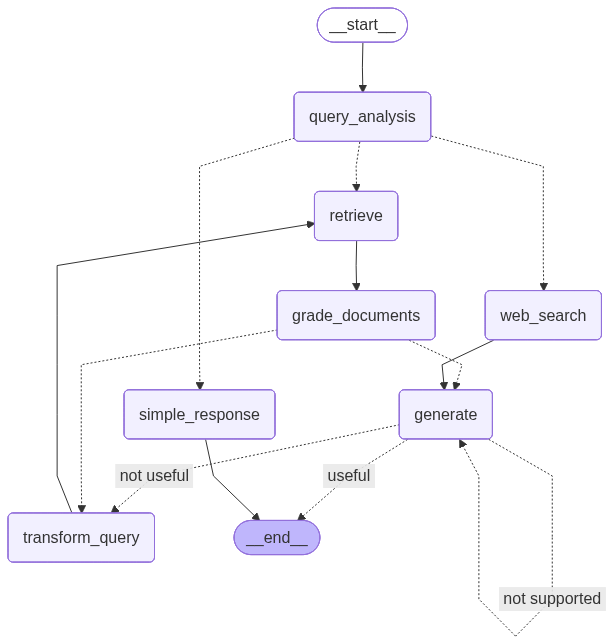

In [23]:
graph 

---

# gradio

In [24]:
! uv pip install langchain-tavily

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Audited 1 package in 16ms


In [25]:
import gradio as gr

# 이 셀은 graph = create_agent_graph() 가 이미 실행된 노트북 안에서 실행해야 합니다.
# (graph 변수가 위쪽 셀에 정의되어 있어야 함)


def respond(message: str, history: list):
    """
    단순(논스트리밍) 버전: 그래프를 끝까지 실행한 뒤 최종 답변만 반환
    """
    result = graph.invoke({"question": message})
    return result.get("generation", "답변을 생성하지 못했습니다.")


def respond_stream(message: str, history: list):
    """
    스트리밍 버전: 노드가 진행되는 동안 중간 상태를 표시하다가
    generation이 채워지면 그 내용으로 화면을 갱신
    """
    partial = ""
    for chunk in graph.stream({"question": message}, stream_mode="updates"):
        for node_name, node_output in chunk.items():
            partial = f"⏳ {node_name} 처리 중...\n\n"
            if "generation" in node_output:
                partial = node_output["generation"]
            yield partial


# ===============================
# Gradio UI 구성 (노트북 셀에서 바로 실행)
# ===============================
with gr.Blocks(title="AI Brief RAG 에이전트") as demo:
    gr.Markdown("## SPRi AI Brief 기반 RAG 에이전트")
    gr.Markdown("AI 기술 질문은 문서에서 검색하고, 일반 질문은 웹 검색으로 답변합니다.")

    gr.ChatInterface(
        fn=respond_stream,   # 최종 답변만 보고 싶으면 respond로 교체
        type="messages",
        examples=[
            "안녕하세요",
            "최근 생성형 AI 정책 동향이 어떻게 되나요?",
            "오늘 서울 날씨 알려줘",
        ],
        title=None,
    )



In [26]:
# 주피터 노트북 셀 안에서 바로 실행 (별도의 if __name__ 가드 불필요)
# inline=True: 노트북 출력 영역에 바로 UI를 띄움
# debug=True: 에러 발생 시 노트북 출력에 트레이스백 표시
# share=False: 외부 공개 링크 생성 안 함 (필요하면 True로 변경)
demo.launch(inline=True, debug=True, share=False)

* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


##### QUERY ANALYSIS #####
Analyzing question: 오늘 서울 날씨 알려줘
Intent: web
##### ROUTE QUESTION #####
---ROUTE DECISION: WEB SEARCH---
##### WEB SEARCH #####
Question: 오늘 서울 날씨 알려줘
Web search completed
##### GENERATE #####
Question: 오늘 서울 날씨 알려줘
Context: {'query': '오늘 서울 날씨 알려줘', 'follow_up_questions': None, 'answer': None, 'images': [], 'results': [{'u...
Response: ## 오늘 서울 날씨

주어진 문서 기준으로 보면, **서울의 오늘 날씨는 대체로 흐리고 습한 편**이며, **오후에 한두 차례 짧은 소나기**가 있을 수 있습니다.  
또한 서울...
##### CHECK HALLUCINATIONS #####
---DECISION: GENERATION IS GROUNDED IN DOCUMENTS---
---DECISION: GENERATION ADDRESSES QUESTION---
##### QUERY ANALYSIS #####
Analyzing question: 안녕하세요"
Intent: simple
##### ROUTE QUESTION #####
---ROUTE DECISION: SIMPLE CONVERSATION---
##### SIMPLE RESPONSE #####
Response: 안녕하세요! 무엇을 도와드릴까요?
##### QUERY ANALYSIS #####
Analyzing question: 최근 생성형 AI 정책 동향이 어떻게 되나요?
Intent: rag
##### ROUTE QUESTION #####
---ROUTE DECISION: RAG SEARCH---
##### RETRIEVE #####
Question: 최근 생성형 AI 정책 동향이 어떻게 되나요?
Re